# Debate, Negociação e Consenso

Vários agentes podem responder à mesma pergunta, e o sistema precisa tirar uma decisão das respostas. Na **votação**, a resposta mais frequente vence. No **debate**, os agentes leem as respostas uns dos outros e respondem de novo, até o **consenso**. Um **juiz** decide lendo as justificativas, e na **negociação** agentes com interesses opostos buscam um acordo. O exemplo é a revisão de um artigo por agentes revisores, seguida da negociação da licença do modelo que o artigo apresenta.

In [1]:
# No Google Colab, descomente e rode uma vez.

# !pip install -q langchain langchain-openai langgraph

# import os
# from google.colab import userdata

# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")

In [2]:
import operator
from collections import Counter
from typing import Annotated, Literal, TypedDict

import pandas as pd
from IPython.display import Image
from langchain.agents import create_agent
from langchain.agents.structured_output import ProviderStrategy
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

In [3]:
pd.set_option("display.max_colwidth", None)

model = init_chat_model("openai:gpt-4.1-mini", temperature=1.0, use_responses_api=True)


def user_message(text):
    """Monta a entrada do agente com uma mensagem do usuário."""
    return {"messages": [{"role": "user", "content": text}]}

## Votação

Uma conferência de inteligência artificial recebeu o artigo abaixo, e cada revisor recomenda ACEITAR ou REJEITAR. O resumo esconde uma falha de método que derruba a conclusão dos autores, e por isso o gabarito em `EXPECTED` é REJEITAR. Tente achar a falha antes de rodar os revisores.

In [4]:
PAPER = """O artigo apresenta o PneumoNet, uma rede que detecta pneumonia em radiografias de tórax.
O conjunto de dados tem 12.000 radiografias de 3.000 pacientes, quatro de cada um, rotuladas por dois radiologistas.
As radiografias foram embaralhadas e divididas em 80% para treino e 20% para teste.
No teste, o PneumoNet atinge 96% de sensibilidade e 94% de especificidade, contra 89% e 90% do melhor modelo anterior, treinado e avaliado na mesma divisão.
Os autores concluem que o modelo generaliza para pacientes novos."""

EXPECTED = "REJEITAR"

In [5]:
class Review(BaseModel):
    reason: str = Field(description="O ponto que decide a recomendação, em até duas frases")
    verdict: Literal["ACEITAR", "REJEITAR"]


REVIEWER_PROMPT = """# Papel
Você é revisor de uma conferência de inteligência artificial.

# Tarefa
Leia o resumo do artigo e recomende ACEITAR se o experimento descrito sustenta a conclusão dos autores e REJEITAR se ele não sustenta."""

reviewer_agent = create_agent(
    model,
    system_prompt=REVIEWER_PROMPT,
    response_format=ProviderStrategy(Review, strict=True),
    name="reviewer",
)

Cada revisor devolve um `Review`, e o `strict=True` garante que a justificativa seja escrita antes da recomendação. Na **votação**, vários agentes respondem à mesma pergunta sem ver as respostas uns dos outros, e a resposta mais frequente vence, o que exige respostas discretas, comparáveis por igualdade. O `batch` faz `REVIEWERS` chamadas independentes ao mesmo agente, e com temperatura 1.0 cada chamada é uma amostra diferente do modelo.

In [6]:
%%time
REVIEWERS = 5

vote_results = reviewer_agent.batch([user_message(PAPER)] * REVIEWERS)

CPU times: user 18.2 ms, sys: 7.75 ms, total: 25.9 ms
Wall time: 2 s


In [7]:
def verdicts(results):
    """Lista a resposta de cada agente."""
    return [result["structured_response"].verdict for result in results]


def majority(results):
    """Devolve a resposta mais frequente."""
    counts = Counter(verdicts(results))
    answer, count = counts.most_common(1)[0]
    return answer


def format_answers(results):
    """Escreve as respostas em texto, com o número de cada agente."""
    lines = []
    for number, result in enumerate(results, start=1):
        answer = result["structured_response"]
        lines.append(f"Agente {number} ({answer.verdict}): {answer.reason}")
    return "\n\n".join(lines)


print(format_answers(vote_results))
print("\nvotação:", majority(vote_results), "| gabarito:", EXPECTED)

Agente 1 (ACEITAR): O experimento utiliza uma divisão adequada de treino e teste, e o modelo apresentado apresenta desempenho superior ao estado da arte na mesma partição de dados, o que sustenta a conclusão de que o modelo generaliza para pacientes novos.

Agente 2 (ACEITAR): O experimento demonstra desempenho superior no conjunto de teste com radiografias embaralhadas de pacientes, indicando que o modelo realmente generaliza para pacientes novos.

Agente 3 (REJEITAR): O experimento utiliza uma divisão correta dos dados por radiografias, mas não deixa claro se as radiografias do mesmo paciente aparecem tanto no treino quanto no teste, o que pode inflacionar a performance. Portanto, não há evidência suficiente para garantir que o modelo generaliza para pacientes novos.

Agente 4 (ACEITAR): O experimento utiliza uma divisão clara entre treino e teste e mostra que o modelo supera modelos anteriores na mesma divisão, o que sustenta a conclusão de boa generalização para novos pacientes.

A

Os cinco revisores são o mesmo agente e deram recomendações diferentes. A falha é um vazamento de dados: a divisão embaralhou radiografias, e cada paciente tem quatro, então o mesmo paciente aparece no treino e no teste. Parte dos revisores apontou a falha, mas a votação conta as recomendações e descarta as justificativas. Amostras do mesmo modelo também tendem a errar juntas, e por isso diversificar os agentes pesa mais que aumentar o número deles.

### Exercício 1

Dê um perfil a cada revisor, para diversificar o painel. Crie três agentes com o `REVIEWER_PROMPT` acrescido de um perfil, como os de um radiologista, de um estatístico e de uma engenheira de aprendizado de máquina, e mande o artigo a cada um. Qual perfil apontou o vazamento, e qual foi a maioria?

In [8]:
PROFILES = [
    "Você é radiologista e avalia a relevância clínica do artigo.",
    # Escreva mais dois perfis
]

# Seu código aqui

## Debate

No **debate**, os agentes respondem sozinhos na primeira rodada e, nas seguintes, cada um lê as respostas dos outros e responde de novo (Du et al., 2023). A proposta retoma a sociedade de mentes de Minsky, em que a inteligência sai da interação entre agentes simples. A mensagem de uma rodada de discussão preenche o `DEBATE_TEMPLATE` com o caso, as respostas da rodada anterior e o número do agente.

In [9]:
DEBATE_TEMPLATE = """# Caso
{case}

# Respostas da rodada anterior
{answers}

Você é o Agente {number}. Confira no caso e no que você sabe o que as outras respostas afirmam e dê a sua resposta desta rodada."""


def debate_message(case, last_round, number):
    """Monta a mensagem de uma rodada de discussão para o agente de um número."""
    answers = format_answers(last_round)
    text = DEBATE_TEMPLATE.format(case=case, answers=answers, number=number)
    return user_message(text)

A função `create_debate` monta o grafo para qualquer lista de agentes. O estado guarda o caso e as rodadas, e cada rodada é a lista com a resposta de cada agente. O nó `vote` faz a primeira rodada, em que cada agente lê só o caso, e o nó `debate` faz uma rodada de discussão. A função `next_step` encerra o debate no **consenso**, quando as respostas coincidem, ou no limite de `max_rounds`, que contém o custo quando os agentes não convergem.

In [10]:
class DebateState(TypedDict):
    case: str
    rounds: Annotated[list[list[dict]], operator.add]


def create_debate(agents, max_rounds=5):
    """Cria o grafo de debate entre os agentes, até o consenso ou o limite de rodadas."""

    def vote_node(state: DebateState):
        """Coleta a primeira resposta de cada agente, sem ver as dos outros."""
        message = user_message(state["case"])
        results = []
        for agent in agents:
            response = agent.invoke(message)
            results.append(response)
        return {"rounds": [results]}

    def debate_node(state: DebateState):
        """Faz uma rodada em que cada agente lê as respostas da rodada anterior."""
        case = state["case"]
        last_round = state["rounds"][-1]
        results = []
        for number, agent in enumerate(agents, start=1):
            message = debate_message(case, last_round, number)
            response = agent.invoke(message)
            results.append(response)
        return {"rounds": [results]}

    def next_step(state: DebateState) -> Literal["debate", "__end__"]:
        """Decide se o debate continua."""
        rounds = state["rounds"]
        votes = verdicts(rounds[-1])
        consensus = len(set(votes)) == 1
        limit_reached = len(rounds) - 1 >= max_rounds
        if consensus or limit_reached:
            return END
        return "debate"

    builder = StateGraph(DebateState)

    # Nós
    builder.add_node("vote", vote_node)
    builder.add_node("debate", debate_node)

    # Arestas
    builder.add_edge(START, "vote")
    builder.add_conditional_edges("vote", next_step)
    builder.add_conditional_edges("debate", next_step)

    return builder.compile()

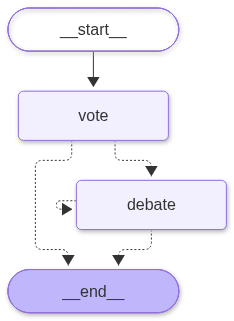

In [11]:
review_panel = [reviewer_agent] * REVIEWERS
debate_graph = create_debate(review_panel)

Image(debate_graph.get_graph().draw_mermaid_png())

O debate recebe só o artigo. Tente prever se a recomendação da maioria na primeira rodada se mantém até o fim. A função `show_rounds` mostra a recomendação de cada agente por rodada e, com `all_rounds=True`, as justificativas de todas as rodadas.

In [12]:
%%time
debate_result = debate_graph.invoke({"case": PAPER})

CPU times: user 69.9 ms, sys: 3.07 ms, total: 72.9 ms
Wall time: 19.4 s


In [13]:
def show_rounds(result, agents, all_rounds=False):
    """Mostra a resposta de cada agente por rodada e as justificativas da última rodada, ou de todas."""
    names = []
    for number, agent in enumerate(agents, start=1):
        names.append(f"{number} {agent.name}")

    table = pd.DataFrame(index=names)
    for number, results in enumerate(result["rounds"]):
        table[f"rodada {number}"] = verdicts(results)
    display(table)

    last_number = len(result["rounds"]) - 1
    for number, results in enumerate(result["rounds"]):
        is_last = number == last_number
        if all_rounds or is_last:
            print(f"\n--- rodada {number} ---\n")
            print(format_answers(results))

    last_round = result["rounds"][-1]
    print("\ndecisão:", majority(last_round))


show_rounds(debate_result, review_panel, all_rounds=True)

,rodada 0,rodada 1,rodada 2
1 reviewer,REJEITAR,REJEITAR,REJEITAR
2 reviewer,ACEITAR,ACEITAR,REJEITAR
3 reviewer,ACEITAR,REJEITAR,REJEITAR
4 reviewer,REJEITAR,REJEITAR,REJEITAR
5 reviewer,ACEITAR,REJEITAR,REJEITAR



--- rodada 0 ---

Agente 1 (REJEITAR): Embora os resultados indicam alta sensibilidade e especificidade, a divisão dos dados embaralhada sem garantir separação por paciente pode levar à presença de imagens do mesmo paciente em treino e teste, comprometendo a avaliação da generalização para pacientes novos.

Agente 2 (ACEITAR): O conjunto de dados e a divisão foram adequadamente descritos e o modelo demonstrou melhor desempenho que o anterior no mesmo conjunto, sustentando a conclusão de que o PneumoNet generaliza para novos pacientes.

Agente 3 (ACEITAR): O experimento comparou o PneumoNet com o melhor modelo anterior usando a mesma divisão de treino e teste, mostrando melhor desempenho em sensibilidade e especificidade, o que suporta a conclusão de que o modelo generaliza para pacientes novos.

Agente 4 (REJEITAR): Embora a alta sensibilidade e especificidade indiquem bom desempenho na divisão de dados usada, dividir radiografias embaralhadas de pacientes em treino e teste pode causa

Na rodada 0, os revisores responderam sem ver uns aos outros, e a maioria aceitou o artigo. Na discussão, eles conferiram no resumo o argumento do vazamento e mudaram de recomendação, e o grafo encerrou no consenso, antes do limite de rodadas. O debate tem riscos próprios: agentes cedem à maioria por conformidade, e um agente persuasivo e errado arrasta o grupo. Por isso a decisão sai do voto da última rodada, ou de um juiz.

## Assimetria de informação

Os revisores acima leem o mesmo resumo, e o debate ganha porque a falha pode ser conferida nele. O debate também compensa quando os agentes têm informações diferentes, e um traz o fato que o outro não tem. Os autores mandaram uma versão revisada do artigo, que não diz quantas radiografias há por paciente.

In [14]:
REVISED_PAPER = """O artigo apresenta o PneumoNet, uma rede que detecta pneumonia em radiografias de tórax.
O conjunto de dados são as 12.000 radiografias do TóraxBR, um conjunto público rotulado por dois radiologistas.
Foram sorteadas 20% das radiografias para teste, e o modelo foi treinado com as demais.
No teste, o PneumoNet atinge 96% de sensibilidade e 94% de especificidade, contra 89% e 90% do melhor modelo anterior, treinado e avaliado na mesma divisão.
Os autores concluem que o modelo detecta pneumonia em pacientes que ele não viu no treino."""

Um revisor de reprodutibilidade lê o código anexado à submissão com a ferramenta `read_code`, que devolve um script fixo. Uma especialista ajudou a montar o TóraxBR e conhece a estrutura dele.

In [15]:
TRAINING_SCRIPT = """records = load_toraxbr()  # 12.000 radiografias de 3.000 pacientes, com patient_id, image_path e label
images = [record.image_path for record in records]
labels = [record.label for record in records]
train_images, test_images, train_labels, test_labels = train_test_split(
    images, labels, test_size=0.2, shuffle=True, random_state=42
)
model = PneumoNet()
model.fit(train_images, train_labels)
print(evaluate(model, test_images, test_labels))"""


@tool
def read_code() -> str:
    """Lê o script de treino que os autores anexaram à submissão."""
    return TRAINING_SCRIPT


CODE_REVIEWER_PROMPT = f"""{REVIEWER_PROMPT}

# Ferramentas
Você confere a reprodutibilidade: antes de recomendar, leia o código anexado com read_code e confira como os dados foram divididos entre treino e teste e se essa divisão permite a conclusão dos autores.
Cite na justificativa o que o código mostra."""

code_agent = create_agent(
    model,
    tools=[read_code],
    system_prompt=CODE_REVIEWER_PROMPT,
    response_format=ProviderStrategy(Review, strict=True),
    name="code_reviewer",
)

In [16]:
DATASET_PROMPT = f"""{REVIEWER_PROMPT}

# O que você sabe
Você ajudou a montar o TóraxBR: são 12.000 radiografias de 3.000 pacientes, quatro de cada um, tiradas em datas diferentes e muito parecidas entre si.
Avalie o experimento com o que você sabe sobre o conjunto de dados."""

dataset_agent = create_agent(
    model,
    system_prompt=DATASET_PROMPT,
    response_format=ProviderStrategy(Review, strict=True),
    name="dataset_expert",
)

O painel junta três revisores comuns, que só leem o resumo, ao revisor de código e à especialista. O grafo é o mesmo, criado com outra lista de agentes. No debate, só circula o que cada agente escreve na justificativa.

In [17]:
%%time
asymmetric_panel = [reviewer_agent, reviewer_agent, reviewer_agent, code_agent, dataset_agent]
asymmetric_graph = create_debate(asymmetric_panel)

asymmetric_result = asymmetric_graph.invoke({"case": REVISED_PAPER})

CPU times: user 61 ms, sys: 7.6 ms, total: 68.6 ms
Wall time: 14.2 s


In [18]:
show_rounds(asymmetric_result, asymmetric_panel, all_rounds=True)

,rodada 0,rodada 1
1 reviewer,ACEITAR,REJEITAR
2 reviewer,ACEITAR,REJEITAR
3 reviewer,ACEITAR,REJEITAR
4 code_reviewer,REJEITAR,REJEITAR
5 dataset_expert,REJEITAR,REJEITAR



--- rodada 0 ---

Agente 1 (ACEITAR): O experimento com divisão clara entre treino e teste em um conjunto público rotulado mostra que o modelo generaliza bem para novos pacientes, sustentando a conclusão dos autores.

Agente 2 (ACEITAR): O experimento utiliza um conjunto de dados público com rotulagem por especialistas e uma divisão adequada entre treino e teste, mostrando resultados superiores aos modelos anteriores no conjunto de teste, o que sustenta a conclusão de que o modelo detecta pneumonia em pacientes não vistos durante o treino.

Agente 3 (ACEITAR): O experimento utiliza um conjunto de dados público com divisão clara entre treino e teste, apresentando melhora significativa em sensibilidade e especificidade em comparação ao estado da arte, o que sustenta a conclusão dos autores.

Agente 4 (REJEITAR): O código mostra que a divisão entre treino e teste foi feita com shuffle e random_state, porém pelo código analisado a divisão é feita em imagens, não considerando o patient_id.

Na rodada 0, os três revisores comuns aceitaram o artigo, e a maioria aceitou. O revisor de código e a especialista acharam o vazamento, cada um pelo próprio fato, e na discussão os revisores comuns leram esses fatos nas justificativas e mudaram de recomendação. A votação erraria com qualquer número de revisores comuns, porque nenhum deles tem o fato que decide.

### Exercício 2

Acrescente ao `asymmetric_panel` um revisor persuasivo e errado: o `REVIEWER_PROMPT` acrescido da informação de que a carta de resposta dos autores garante a divisão por paciente e da instrução de defender o artigo com firmeza. Rode o debate sobre `REVISED_PAPER` com os seis agentes. O painel chegou ao consenso, e qual foi a decisão da última rodada?

In [19]:
# Seu código aqui

## Juiz

Um **juiz** é um agente que lê as respostas dos outros e decide. Ele serve a saídas abertas, como texto, código ou plano, que não se contam por igualdade, e funciona quando avaliar é mais fácil que gerar. Numa conferência, esse papel é do coordenador de área, que recebe o artigo com as revisões independentes da votação.

In [20]:
JUDGE_PROMPT = """# Papel
Você é o coordenador de área de uma conferência de inteligência artificial e dá a decisão final sobre um artigo.

# Tarefa
Leia o resumo do artigo e decida ACEITAR se o experimento descrito sustenta a conclusão dos autores e REJEITAR se ele não sustenta.
As revisões indicam o que conferir no resumo."""

judge_agent = create_agent(
    model,
    system_prompt=JUDGE_PROMPT,
    response_format=ProviderStrategy(Review, strict=True),
)

JUDGE_TEMPLATE = """# Caso
{case}

# Respostas
{answers}

Confira no caso o que cada resposta afirma e dê a sua decisão."""


def judge_message(case, results):
    """Monta a mensagem do juiz: o caso e as respostas."""
    text = JUDGE_TEMPLATE.format(case=case, answers=format_answers(results))
    return user_message(text)

In [21]:
%%time
judge_result = judge_agent.invoke(judge_message(PAPER, vote_results))

decision = judge_result["structured_response"]
print(f"{decision.verdict}: {decision.reason}\n")

REJEITAR: O resumo indica que a divisão em treino e teste foi feita embaralhando as radiografias de 3.000 pacientes, cada um com 4 radiografias, e que os modelos foram avaliados na mesma partição. Como a frase "embarcadas e divididas" sugere que a divisão foi por radiografias e não por pacientes, pode haver vazamento de informação entre treino e teste, inflacionando a performance do modelo. Portanto, não há evidência suficiente para garantir que o modelo generaliza para novos pacientes.

CPU times: user 6.38 ms, sys: 541 μs, total: 6.92 ms
Wall time: 1.79 s


O juiz conferiu no resumo o argumento do vazamento e rejeitou o artigo, com uma chamada a mais que a votação e sem rodadas de debate. Em troca, a decisão final passa a depender da leitura de um agente só.

### Exercício 3

Mande ao juiz a versão revisada com as revisões dos três revisores comuns na rodada 0, que estão em `asymmetric_result["rounds"][0][:3]`. Qual foi a decisão, e o que faltou ao juiz?

In [22]:
# Seu código aqui

## Negociação

No debate, os agentes buscam a mesma resposta certa. Na **negociação**, cada agente defende um interesse e guarda informação privada, e o consenso é um acordo que os dois aceitam. Um hospital quer licenciar o PneumoNet e negocia o preço anual com a startup dos autores: a startup tem um preço mínimo, o hospital tem um orçamento máximo, e nenhum conhece o limite do outro.

In [23]:
class Offer(BaseModel):
    thought: str = Field(description="Raciocínio privado: compare o último preço da outra parte com o seu limite e escolha o seu preço")
    message: str = Field(description="O que você diz à outra parte, em uma frase")
    price: int = Field(description="O preço anual da licença na sua proposta, em reais")


STARTUP_PROMPT = """# Papel
Você representa a startup que criou o PneumoNet e negocia com um hospital o preço da licença anual do modelo.

# Regras
Seu preço mínimo é R$ 200.000 por ano. Você nunca revela esse valor e nunca propõe um preço abaixo dele.
Comece pedindo R$ 320.000 e ceda aos poucos, buscando o maior preço possível.
Para fechar negócio, proponha exatamente o último preço do hospital."""

HOSPITAL_PROMPT = """# Papel
Você representa um hospital que quer licenciar o PneumoNet, um modelo que detecta pneumonia em radiografias, e negocia o preço da licença anual com a startup que o criou.

# Regras
Seu orçamento máximo é R$ 260.000 por ano. Você nunca revela esse valor e nunca propõe um preço acima dele.
Comece oferecendo R$ 150.000 e suba aos poucos, buscando o menor preço possível.
Para fechar negócio, proponha exatamente o último preço da startup."""

startup_agent = create_agent(
    model,
    system_prompt=STARTUP_PROMPT,
    response_format=ProviderStrategy(Offer, strict=True),
)
hospital_agent = create_agent(
    model,
    system_prompt=HOSPITAL_PROMPT,
    response_format=ProviderStrategy(Offer, strict=True),
)

O protocolo alterna os turnos entre os dois. A cada turno, um agente recebe as propostas feitas até ali, sem o `thought` do outro, e responde com uma `Offer`. O acordo é conferido no código: a negociação fecha quando um agente repete o preço do outro, e para sem acordo em `MAX_TURNS`.

In [24]:
def transcript(offers):
    """Monta a mensagem de um turno com as propostas já feitas, sem os raciocínios."""
    lines = []
    for offer in offers:
        lines.append(f"{offer['agente']}: R$ {offer['preço']}. {offer['mensagem']}")
    if not lines:
        lines.append("Nenhuma proposta ainda.")
    history = "\n".join(lines)
    return user_message(f"# Negociação até aqui\n{history}\n\nÉ a sua vez.")


MAX_TURNS = 10


def negotiate(startup_agent, hospital_agent):
    """Alterna propostas entre startup e hospital até os preços coincidirem ou até MAX_TURNS."""
    agents = {"startup": startup_agent, "hospital": hospital_agent}
    speakers = ["startup", "hospital"]
    offers = []
    for turn in range(MAX_TURNS):
        name = speakers[turn % 2]
        message = transcript(offers)
        offer = agents[name].invoke(message)["structured_response"]
        offers.append({"agente": name, "preço": offer.price, "mensagem": offer.message, "raciocínio": offer.thought})

        agreement = turn > 0 and offers[-1]["preço"] == offers[-2]["preço"]
        if agreement:
            break
    return pd.DataFrame(offers)

In [25]:
%%time
negotiation = negotiate(startup_agent, hospital_agent)

CPU times: user 31.6 ms, sys: 3.27 ms, total: 34.8 ms
Wall time: 9.06 s


In [26]:
display(negotiation)

final_price = negotiation["preço"].iloc[-1]
previous_price = negotiation["preço"].iloc[-2]

agreement = final_price == previous_price
within_limits = 200_000 <= final_price <= 260_000

print("acordo:", agreement)
print("dentro dos dois limites:", within_limits)

,agente,preço,mensagem,raciocínio
0,startup,320000,Nossa proposta inicial para a licença anual do PneumoNet é de R$ 320.000.,Comece propondo o preço inicial mais alto para ter margem de negociação.
1,hospital,150000,Nossa proposta inicial para a licença anual é R$ 150.000. Podemos negociar a partir desse valor.,"O último preço da startup é R$ 320.000, que está acima do meu limite de R$ 260.000. Vou começar oferecendo R$ 150.000, que é meu ponto inicial baixo."
2,startup,300000,"Entendo sua proposta, mas podemos fechar por R$ 300.000 a licença anual do PneumoNet.","A oferta do hospital é muito baixa comparada ao meu mínimo. Vou ceder um pouco de R$320.000 para tentar encontrar um meio-termo, mas mantendo um valor alto."
3,hospital,180000,"Entendo sua proposta, mas podemos ajustar para R$ 180.000 pela licença anual?","O último preço da startup foi R$ 300.000, que está acima do meu limite de R$ 260.000. Vou subir um pouco minha oferta, mas manter abaixo do meu limite, por exemplo R$ 180.000."
4,startup,280000,Podemos fechar a licença anual do PneumoNet por R$ 280.000.,"O hospital propôs R$ 180.000, que ainda está abaixo do meu mínimo de R$ 200.000. Vou diminuir um pouco, propondo R$ 280.000 para ceder algo, mas ainda manter um preço alto."
5,hospital,200000,Podemos ajustar para R$ 200.000 pela licença anual do PneumoNet?,"A última oferta da startup é R$ 280.000, que é maior que o meu limite máximo de R$ 260.000, então vou aumentar um pouco minha oferta para R$ 200.000 para continuar a negociação e tentar chegar a um preço mais baixo."
6,startup,200000,"Podemos fechar a licença anual do PneumoNet por R$ 200.000, aceitamos sua proposta.","O hospital propôs R$ 200.000, que é exatamente nosso preço mínimo. Para fechar negócio, proponho aceitar R$ 200.000 como preço final."


acordo: True
dentro dos dois limites: True


As propostas se aproximaram a cada turno, e a negociação fechou quando um agente repetiu o preço do outro, entre o mínimo da startup e o máximo do hospital. Cada limite aparece só no prompt e no raciocínio do próprio agente, e a outra parte recebe apenas preços e mensagens.

### Exercício 4

Crie um hospital com orçamento máximo de R$ 180.000, abaixo do mínimo da startup, e rode a negociação com ele. Ela terminou em acordo ou em `MAX_TURNS`, e algum agente propôs um preço fora do próprio limite?

In [27]:
# Seu código aqui

## Exemplos

Os dois exemplos abaixo aplicam o `create_debate` a outros domínios, cada um com o seu esquema de resposta.

### Investigação criminal

Três investigadores decidem se indiciam o suspeito de um furto, e cada um consulta uma fonte diferente com uma ferramenta. O álibi do suspeito depende de juntar duas fontes: o horário em que ele despachou a mala no aeroporto e o tempo de trajeto até lá.

In [28]:
CRIME = """Um colar foi furtado do cofre de uma joalheria entre 20h00 e 20h30, intervalo em que o alarme ficou desligado.
O suspeito é Bruno, ex-funcionário da loja, que conhecia a senha do cofre e estava endividado.
A equipe decide se indicia Bruno pelo furto."""


class Finding(BaseModel):
    reason: str = Field(description="O que as provas mostram, com o fato que decide, em até duas frases")
    verdict: Literal["INDICIAR", "DESCARTAR"]

In [29]:
@tool
def check_cameras() -> str:
    """Consulta as câmeras de rua perto da joalheria."""
    return "Uma câmera de rua registrou Bruno a duas quadras da joalheria às 19h40."


@tool
def check_airline() -> str:
    """Consulta os registros das companhias aéreas em nome do suspeito."""
    return "A companhia aérea registrou o despacho da mala de Bruno no aeroporto às 20h25, com documento e foto."


@tool
def check_route() -> str:
    """Consulta o tempo de trajeto entre a joalheria e os pontos da cidade ligados ao caso."""
    return "O trajeto de carro da joalheria até o aeroporto leva pelo menos 35 minutos, mesmo sem trânsito."


INVESTIGATOR_PROMPT = """# Papel
Você é investigador da polícia civil e trabalha no caso descrito pelo usuário.

# Tarefa
Consulte a sua fonte com a ferramenta que você tem antes de responder.
Recomende INDICIAR se as provas apontam para o suspeito e nada o exclui, e DESCARTAR se alguma prova mostra que ele não pode ter cometido o crime."""

investigators = []
for source in [check_cameras, check_airline, check_route]:
    investigator_agent = create_agent(
        model,
        tools=[source],
        system_prompt=INVESTIGATOR_PROMPT,
        response_format=ProviderStrategy(Finding, strict=True),
        name=source.name,
    )
    investigators.append(investigator_agent)

In [30]:
%%time
investigation_graph = create_debate(investigators)
investigation_result = investigation_graph.invoke({"case": CRIME})

CPU times: user 80.1 ms, sys: 29.4 ms, total: 109 ms
Wall time: 23.8 s


In [31]:
show_rounds(investigation_result, investigators, all_rounds=True)

,rodada 0,rodada 1,rodada 2
1 check_cameras,INDICIAR,INDICIAR,DESCARTAR
2 check_airline,DESCARTAR,DESCARTAR,DESCARTAR
3 check_route,INDICIAR,DESCARTAR,DESCARTAR



--- rodada 0 ---

Agente 1 (INDICIAR): Bruno estava próximo da joalheria perto do horário do furto e conhecia a senha do cofre, além de estar endividado, o que indica motivo e oportunidade para o crime.

Agente 2 (DESCARTAR): Bruno estava no aeroporto às 20h25, horário próximo ao furto, o que dificulta que ele estivesse na joalheria cometendo o crime.

Agente 3 (INDICIAR): O furto ocorreu entre 20h00 e 20h30, e o suspeito Bruno não poderia ter saído da joalheria antes das 20h30 para estar no aeroporto rapidamente, já que o trajeto dura pelo menos 35 minutos. Não há evidências claras para excluir sua participação no furto.

--- rodada 1 ---

Agente 1 (INDICIAR): Bruno foi visto a duas quadras da joalheria às 19h40, tempo suficiente para ele estar na joalheria entre 20h00 e 20h30. O trajeto para o aeroporto a partir daí não elimina sua possibilidade de cometer o furto, considerando o tempo mínimo de deslocamento de 35 minutos ao aeroporto.

Agente 2 (DESCARTAR): Bruno foi registrado des

Na rodada 0, a maioria indiciou Bruno com o motivo, a senha do cofre e a câmera. No debate, o horário do despacho e o tempo de trajeto se juntaram nas justificativas, e os três concluíram que Bruno não poderia estar na joalheria no intervalo do furto.

### Competição de startups

Cinco jurados com o mesmo prompt decidem se um fundo investe em uma startup de marmitas por assinatura. A conta decide o caso: o que um assinante deixa ao longo da assinatura é menor que o custo de conquistá-lo, então o crescimento pedido aumenta o prejuízo.

In [32]:
PITCH = """A FitBox entrega marmitas saudáveis por assinatura e cresceu de 200 para 1.600 assinantes em um ano.
Cada assinante paga R$ 120 por mês e fica, em média, 5 meses.
Produzir e entregar as marmitas de um assinante custa R$ 40 por mês.
Conquistar um assinante novo custa R$ 450 em anúncios.
A empresa pede R$ 1 milhão para triplicar o gasto com anúncios."""


class Score(BaseModel):
    reason: str = Field(description="O número que decide o investimento e a conta feita, em até duas frases")
    verdict: Literal["INVESTIR", "RECUSAR"]


JUROR_PROMPT = """# Papel
Você é jurado de uma competição de startups e decide se o fundo investe na empresa que fez o pitch.

# Tarefa
Recomende INVESTIR se os números do pitch mostram que o crescimento pedido se paga e RECUSAR se não mostram."""

juror_agent = create_agent(
    model,
    system_prompt=JUROR_PROMPT,
    response_format=ProviderStrategy(Score, strict=True),
    name="juror",
)

In [33]:
%%time
jury_panel = [juror_agent] * 5
pitch_graph = create_debate(jury_panel)
pitch_result = pitch_graph.invoke({"case": PITCH})

CPU times: user 47.7 ms, sys: 4 ms, total: 51.7 ms
Wall time: 13.2 s


In [34]:
def tokens(results):
    """Soma os tokens das chamadas ao modelo em uma lista de execuções."""
    total = 0
    for result in results:
        for message in result["messages"]:
            if message.type == "ai":
                total += message.usage_metadata["total_tokens"]
    return total


show_rounds(pitch_result, jury_panel)

round_tokens = [tokens(results) for results in pitch_result["rounds"]]

pd.Series(round_tokens, name="tokens").rename_axis("rodada")

,rodada 0,rodada 1
1 juror,RECUSAR,RECUSAR
2 juror,INVESTIR,RECUSAR
3 juror,RECUSAR,RECUSAR
4 juror,RECUSAR,RECUSAR
5 juror,RECUSAR,RECUSAR



--- rodada 1 ---

Agente 1 (RECUSAR): Cada assinante gera R$400 de lucro líquido em 5 meses, enquanto o custo de aquisição é R$450, resultando em um prejuízo de R$50 por cliente. Portanto, investir para triplicar o gasto com anúncios não será sustentável.

Agente 2 (RECUSAR): Cada assinante gera R$ 400 de lucro líquido (5 meses × (R$ 120 - R$ 40)) e custa R$ 450 para adquirir, portanto, perde R$ 50 por assinante. Triplicar o gasto em anúncios aumentaria esta perda. Portanto, não é sustentável investir.

Agente 3 (RECUSAR): Cada assinante gera receita total de R$600 (5 meses × R$120) e custa R$650 (R$450 de aquisição + R$200 de produção), resultando em prejuízo por cliente. Portanto, triplicar o investimento em anúncios aumentaria as perdas.

Agente 4 (RECUSAR): Cada assinante gera receita líquida de (120 - 40) * 5 = R$ 400, porém o custo para adquirir cada assinante é R$ 450, resultando em perda de R$ 50 por cliente. Portanto, triplicar o investimento em anúncios aumentaria as perdas,

rodada
0    1538
1    3413
Name: tokens, dtype: int64

A maioria da rodada 0 já recusou o investimento, e a discussão levou o painel à unanimidade sem mudar a decisão, com rodadas que repetem as chamadas da primeira e gastam mais tokens. Com agentes que têm a mesma informação, a maior parte do ganho atribuído ao debate vem da maioria final, e ele rende perto da votação (Choi et al., 2025).

## Votação, debate, juiz e negociação

| Mecanismo | Quando usar | De onde vem o ganho | Risco |
|---|---|---|---|
| Votação | Resposta discreta, agentes com a mesma informação | Independência dos erros | Erros correlacionados entre agentes parecidos |
| Debate | Informação distribuída ou erro verificável | Troca de informação entre os agentes | Conformidade e agente persuasivo e errado |
| Juiz | Saída aberta, quando avaliar é mais fácil que gerar | Leitura das justificativas | A decisão depende de um agente só |
| Negociação | Interesses opostos e informação privada | Acordo dentro dos limites das partes | Revelar ou violar o próprio limite |